# Hotel review sentiment: walkthrough

**Business question:** a hotel group receives thousands of reviews. Can a model flag the unhappy guests, so a customer-care team reads a small share of reviews but still reaches most of those guests?

**How to run it**
- **Parts 1a–1d** (data validation, cleaning, EDA, feature engineering) run live on the raw Kaggle file `data/Hotel_Reviews.csv` (515K reviews, about 230 MB). The file isn't stored in the repository because of Kaggle's licence; see `data/README.md`. Without it, those cells skip and the saved outputs below show the full run.
- **Parts 2–8** read the reports saved in the repository and need no download.

To retrain the model from scratch, run `python -m hotel_sentiment.train`.

| Part | Question |
|---|---|
| 1 | Data: from 515,738 raw reviews to a clean, labelled dataset |
| 1a | Data validation: completeness, validity, consistency, accuracy |
| 1b | Cleaning, run live with the project's own code |
| 1c | Exploratory data analysis and hypothesis tests |
| 1d | Feature engineering: from text to TF-IDF features, fitted on training hotels only |
| 2 | Validation design: why the test set is made of **hotels the model never saw** |
| 3 | Baselines, a screen of 11 model families, and the final model |
| 4 | Choosing the operating point: what the team actually reads |
| 5 | Is the result robust? (repeated splits, label definition, unseen text, behavioural tests, subgroups) |
| 6 | Class imbalance: does balancing help, and what does leaky SMOTE do? |
| 7 | Explanations: SHAP |
| 8 | Error analysis and conclusions |

In [1]:
import json, subprocess, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import Image, display

ROOT = Path("..") if (Path("..") / "reports").exists() else Path("Hotel-Review-Sentiment-Analysis")
if not (ROOT / "reports").exists():          # opened on its own (e.g. in Colab): fetch the repository
    subprocess.run(["git", "clone", "-q", "https://github.com/Muneera-DSA/Hotel-Review-Sentiment-Analysis.git"], check=True)
REP, FIG = ROOT / "reports", ROOT / "reports" / "figures"
metrics = json.loads((REP / "metrics.json").read_text())
val = json.loads((REP / "validation.json").read_text())
pd.set_option("display.max_colwidth", 120)
sys.path.insert(0, str(ROOT / "src"))     # use the project's own cleaning code
RAW_PATH = ROOT / "data" / "Hotel_Reviews.csv"
HAVE_RAW = RAW_PATH.exists()
SKIP = "skipped: data/Hotel_Reviews.csv not found (see data/README.md). Saved outputs show the full run."
print("raw data available:", HAVE_RAW)
print("reports:", sorted(p.name for p in REP.glob("*.*")))

raw data available: True
reports: ['.gitkeep', 'error_analysis.csv', 'imbalance_comparison.json', 'imbalance_comparison.md', 'metrics.json', 'metrics.md', 'model_screen.json', 'model_screen.md', 'shap_examples.json', 'shap_global.csv', 'top_terms.csv', 'validation.json', 'validation.md']


## Part 1: data

In [2]:
d = metrics["data"]
steps = pd.DataFrame([
    ("raw reviews", d["raw_rows"]),
    ("remove exact duplicate rows", d["after_exact_duplicate_removal"]),
    ("remove reviews with no text", d["after_empty_text_removal"]),
    ("remove ambiguous mid-range scores (not clearly happy or unhappy)", d["after_empty_text_removal"] - d["ambiguous_band_removed"]),
    ("remove duplicated review text", d["after_text_duplicate_removal"]),
], columns=["step", "reviews remaining"])
steps["removed"] = (-steps["reviews remaining"].diff()).fillna(0).astype(int)
display(steps)
print(f"final: {d['final_rows']:,} reviews from {d['n_hotels']:,} hotels; share of unhappy (negative) reviews: {d['negative_rate']:.1%}")

,step,reviews remaining,removed
0,raw reviews,515738,0
1,remove exact duplicate rows,515173,565
2,remove reviews with no text,514929,244
3,remove ambiguous mid-range scores (not clearly happy or unhappy),365801,149128
4,remove duplicated review text,363666,2135


final: 363,666 reviews from 1,492 hotels; share of unhappy (negative) reviews: 8.4%


**Label definition:** a review is *negative* if the guest scored the stay 5 or below, and *positive* if 8 or above (scores run 2.5–10). Reviews in the ambiguous middle band are removed rather than forced into a class. Part 5 checks that the conclusions don't depend on where those cut-offs are drawn.

**Text:** the review's positive and negative text fields are combined. Booking.com placeholders such as "No Negative" are removed, so the model can't read the label from a template phrase.

## Part 1a: data validation

Before any modelling, the raw file is checked on four dimensions:
- **Completeness:** what is missing?
- **Validity:** are values in their allowed range and format?
- **Consistency:** do related columns agree with each other?
- **Accuracy:** do the numbers match an independent reference?

In [3]:
if HAVE_RAW:
    raw = pd.read_csv(RAW_PATH)
    print(f"{len(raw):,} rows x {raw.shape[1]} columns; {raw.Hotel_Name.nunique():,} hotel names; {raw.Hotel_Address.nunique():,} addresses")
    comp = pd.DataFrame({"dtype": raw.dtypes.astype(str), "missing": raw.isna().sum(), "missing %": (raw.isna().mean() * 100).round(2),
                         "used by the model?": ["yes" if c in ("Hotel_Name", "Review_Date", "Positive_Review", "Negative_Review", "Reviewer_Score")
                                                else "no" for c in raw.columns]})
    display(comp)
else:
    print(SKIP)

515,738 rows x 17 columns; 1,492 hotel names; 1,493 addresses


,dtype,missing,missing %,used by the model?
Hotel_Address,str,0,0.00,no
Additional_Number_of_Scoring,int64,0,0.00,no
Review_Date,str,0,0.00,yes
Average_Score,float64,0,0.00,no
Hotel_Name,str,0,0.00,yes
Reviewer_Nationality,str,0,0.00,no
Negative_Review,str,0,0.00,yes
Review_Total_Negative_Word_Counts,int64,0,0.00,no
Total_Number_of_Reviews,int64,0,0.00,no
Positive_Review,str,0,0.00,yes


**Completeness:** only `lat` and `lng` have missing values (0.6% of rows), and neither is used by the model. All five modelling columns are complete.

In [4]:
if HAVE_RAW:
    dates = pd.to_datetime(raw.Review_Date, format="%m/%d/%Y", errors="coerce")
    neg_field, pos_field = raw.Negative_Review.str.strip(), raw.Positive_Review.str.strip()
    checks = pd.DataFrame([
        ("validity", "Reviewer_Score within 2.5-10", raw.Reviewer_Score.between(2.5, 10).mean()),
        ("validity", "Review_Date parses as m/d/YYYY", dates.notna().mean()),
        ("validity", "Average_Score within 1-10", raw.Average_Score.between(1, 10).mean()),
        ("consistency", "negative word count = words in Negative_Review (0 for the placeholder)",
         ((neg_field.eq("No Negative") & raw.Review_Total_Negative_Word_Counts.eq(0)) |
          (raw.Negative_Review.str.split(" ").str.len() == raw.Review_Total_Negative_Word_Counts)).mean()),
        ("consistency", "each hotel has one Average_Score", (raw.groupby("Hotel_Name").Average_Score.nunique() == 1).mean()),
        ("consistency", "each hotel name has one address", (raw.groupby("Hotel_Name").Hotel_Address.nunique() == 1).mean()),
        ("uniqueness", "rows that are not exact duplicates", 1 - raw.duplicated().mean()),
    ], columns=["dimension", "check", "share passing"])
    display(checks.style.format({"share passing": "{:.4%}"}).hide(axis="index"))
    print(f"review dates: {dates.min():%d %b %Y} to {dates.max():%d %b %Y}")
    print(f"placeholder text: 'No Negative' in {neg_field.eq('No Negative').mean():.1%} of rows, 'No Positive' in {pos_field.eq('No Positive').mean():.1%}")
    multi = raw.groupby("Hotel_Name").Hotel_Address.nunique()
    display(raw[raw.Hotel_Name.isin(multi[multi > 1].index)][["Hotel_Name", "Hotel_Address"]].drop_duplicates())
else:
    print(SKIP)

dimension,check,share passing
validity,Reviewer_Score within 2.5-10,100.0000%
validity,Review_Date parses as m/d/YYYY,100.0000%
validity,Average_Score within 1-10,100.0000%
consistency,negative word count = words in Negative_Review (0 for the placeholder),99.9988%
consistency,each hotel has one Average_Score,99.9330%
consistency,each hotel name has one address,99.9330%
uniqueness,rows that are not exact duplicates,99.8980%


review dates: 04 Aug 2015 to 03 Aug 2017
placeholder text: 'No Negative' in 24.8% of rows, 'No Positive' in 7.0%


,Hotel_Name,Hotel_Address
285876,Hotel Regina,Bergara 2 4 Eixample 08002 Barcelona Spain
433920,Hotel Regina,Rooseveltplatz 15 09 Alsergrund 1090 Vienna Austria
472196,Hotel Regina,Via Cesare Correnti 13 Milan City Center 20123 Milan Italy


**What the checks show**
- Scores, dates and word counts are all valid and internally consistent. Word counts disagree with the text in only 6 of 515,738 rows.
- **Placeholders:** Booking.com writes "No Negative" or "No Positive" when a guest leaves a box empty. They are not guest language. Part 1c shows why they must be removed.
- **One identity problem:** "Hotel Regina" is three different hotels, in Barcelona, Vienna and Milan. Because the split groups reviews by hotel name, all three land on the same side of the train/test split. That is conservative (no leakage), and it affects about 0.1% of reviews.

In [5]:
if HAVE_RAW:
    hotel = raw.groupby(["Hotel_Name", "Hotel_Address"]).agg(average_score=("Average_Score", "first"), mean_score_in_file=("Reviewer_Score", "mean"),
                                                           reviews_in_file=("Reviewer_Score", "size"), total_reviews_on_site=("Total_Number_of_Reviews", "max"))
    r = stats.pearsonr(hotel.average_score, hotel.mean_score_in_file)
    print(f"accuracy check, hotel Average_Score vs mean of its reviews in this file: r = {r.statistic:.3f}, "
          f"median absolute gap {(hotel.average_score - hotel.mean_score_in_file).abs().median():.2f} points")
    print(f"this file holds a median {(hotel.reviews_in_file / hotel.total_reviews_on_site).median():.0%} of each hotel's reviews on the site")
else:
    print(SKIP)

accuracy check, hotel Average_Score vs mean of its reviews in this file: r = 0.964, median absolute gap 0.09 points
this file holds a median 23% of each hotel's reviews on the site


**Accuracy:** each hotel's published `Average_Score` agrees closely with the average of its reviews in the file (r ≈ 0.96, typical gap under 0.1 points). So the scores, and therefore the labels, are recorded faithfully.

The file is a **sample**: it holds roughly a quarter of each hotel's reviews on Booking.com. `Average_Score` is also computed over reviews that include the one being predicted, so it is **excluded as a feature** (target leakage).

## Part 1b: cleaning, run live

The notebook calls the same `build_dataset()` function the training pipeline uses, then checks that the result equals the counts saved in `reports/metrics.json`.

In [6]:
if HAVE_RAW:
    from hotel_sentiment.data import build_dataset, load_raw, split_by_hotel
    from hotel_sentiment.preprocess import normalise, strip_placeholder
    df, audit = build_dataset(load_raw(RAW_PATH))
    saved = metrics["data"]
    print("identical to the saved pipeline run:", all(audit[k] == saved[k] for k in saved if k != "negative_rate"))
    display(pd.DataFrame({"this run": audit, "saved run": saved}).loc[list(saved)])
    print(f"label: negative if score <= 5, positive if score >= 8; {audit['ambiguous_band_removed']:,} mid-range reviews (5 < score < 8) removed")
else:
    print(SKIP)

identical to the saved pipeline run: True


,this run,saved run
raw_rows,515738.000000,515738.000000
after_exact_duplicate_removal,515173.000000,515173.000000
after_empty_text_removal,514929.000000,514929.000000
ambiguous_band_removed,149128.000000,149128.000000
after_text_duplicate_removal,363666.000000,363666.000000
final_rows,363666.000000,363666.000000
negative_rate,0.083989,0.083989
n_hotels,1492.000000,1492.000000


label: negative if score <= 5, positive if score >= 8; 149,128 mid-range reviews (5 < score < 8) removed


## Part 1c: exploratory data analysis

These questions decide how the model is built:
- How unbalanced are the classes?
- How concentrated is the data in a few hotels?
- Does the negative rate vary by city or over time?
- Is review length informative?

class balance: 8.4% negative (30,544 of 363,666)
reviews per hotel: median 140, max 3,073; top 10% of hotels hold 39% of reviews


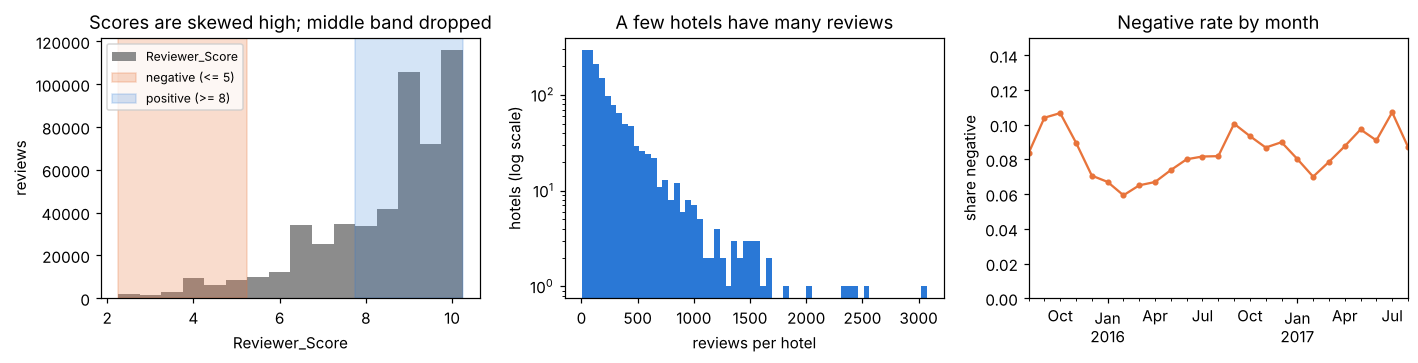

In [7]:
if HAVE_RAW:
    df["city"] = df.Hotel_Address.str.split().str[-1].replace({"Kingdom": "London", "Spain": "Barcelona", "France": "Paris",
                                                               "Netherlands": "Amsterdam", "Austria": "Vienna", "Italy": "Milan"})
    df["words"] = df.text.str.split().str.len()
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
    raw.Reviewer_Score.plot.hist(bins=np.arange(2.25, 10.5, 0.5), ax=ax[0], color="#8c8c8c")
    ax[0].axvspan(2.25, 5.25, color="#e8743b", alpha=0.25, label="negative (<= 5)")
    ax[0].axvspan(7.75, 10.25, color="#2a78d6", alpha=0.2, label="positive (>= 8)")
    ax[0].set(xlabel="Reviewer_Score", ylabel="reviews", title="Scores are skewed high; middle band dropped"); ax[0].legend(fontsize=8)
    per_hotel = df.Hotel_Name.value_counts()
    per_hotel.plot.hist(bins=60, ax=ax[1], color="#2a78d6", log=True)
    ax[1].set(xlabel="reviews per hotel", ylabel="hotels (log scale)", title="A few hotels have many reviews")
    df.set_index("Review_Date").is_negative.resample("ME").mean().plot(ax=ax[2], color="#e8743b", marker="o", ms=3)
    ax[2].set(ylabel="share negative", xlabel="", title="Negative rate by month", ylim=(0, 0.15))
    plt.tight_layout(); plt.show()
    print(f"class balance: {df.is_negative.mean():.1%} negative ({df.is_negative.sum():,} of {len(df):,})")
    print(f"reviews per hotel: median {per_hotel.median():.0f}, max {per_hotel.max():,}; top 10% of hotels hold {per_hotel.head(len(per_hotel) // 10).sum() / len(df):.0%} of reviews")
else:
    print(SKIP)

**Reading this**
- **Imbalance:** about 1 review in 12 is negative. Accuracy would be misleading (a model that always says "positive" scores 92%), so the project uses PR-AUC and recall on negative reviews.
- **Concentration:** the top 10% of hotels hold about 39% of reviews. A random split would put most reviews of a large hotel on both sides, which is why the test set is made of unseen hotels (Part 2).
- **Time:** the monthly negative rate moves between 6% and 11% with no trend. Part 5 checks a train-on-older, test-on-newer split anyway.

In [8]:
if HAVE_RAW:
    by_city = df.groupby("city").agg(reviews=("is_negative", "size"), negative_rate=("is_negative", "mean")).sort_values("negative_rate")
    chi2, p_city, dof, _ = stats.chi2_contingency(pd.crosstab(df.city, df.is_negative))
    n = len(df); cramers_v = np.sqrt(chi2 / (n * dof))
    length = df.groupby("is_negative").words.describe()[["mean", "25%", "50%", "75%"]].rename(index={0: "positive", 1: "negative"})
    neg_w, pos_w = df.words[df.is_negative == 1], df.words[df.is_negative == 0]
    u = stats.mannwhitneyu(neg_w, pos_w)
    auc_len = u.statistic / (len(neg_w) * len(pos_w))
    display(by_city.round(3)); display(length.round(1))
    tests = pd.DataFrame([
        ("H1: negative rate differs by city", "chi-square", f"{p_city:.1e}", f"Cramér's V = {cramers_v:.3f}"),
        ("H2: negative reviews are longer", "Mann-Whitney U", "< 1e-300", f"P(longer) = {auc_len:.2f}"),
    ], columns=["hypothesis", "test", "p-value", "effect size"])
    display(tests.style.hide(axis="index"))
else:
    print(SKIP)

,reviews,negative_rate
city,,
Vienna,28723,0.060
Barcelona,44364,0.065
Amsterdam,41331,0.074
Paris,43012,0.084
Milan,26171,0.088
London,180065,0.094


,mean,25%,50%,75%
is_negative,,,,
positive,30.1,10.0,20.0,38.0
negative,50.9,15.0,32.0,65.0


hypothesis,test,p-value,effect size
H1: negative rate differs by city,chi-square,1.0e-151,Cramér's V = 0.020
H2: negative reviews are longer,Mann-Whitney U,< 1e-300,P(longer) = 0.62


**Statistical vs practical significance.** With 363,666 reviews almost any difference is "significant", so the effect sizes are what matter:
- **City:** the negative rate runs from 6% (Vienna) to 9.4% (London), but Cramér's V is about 0.02, a negligible effect. City is not used as a feature, and Part 5 shows the model performs similarly in every city.
- **Length:** negative reviews are longer (median 32 words vs 20). A random negative review is longer than a random positive one about 62% of the time. That is real but weak, which is why review length is kept as a **baseline** the text model must clearly beat (Part 3).

In [9]:
if HAVE_RAW:
    lab = np.where(raw.Reviewer_Score <= 5, "negative", np.where(raw.Reviewer_Score >= 8, "positive", None))
    ph = (pd.DataFrame({"label": lab, "'No Negative' placeholder": raw.Negative_Review.str.strip().eq("No Negative"),
                        "'No Positive' placeholder": raw.Positive_Review.str.strip().eq("No Positive")})
          .dropna().groupby("label").mean())
    display(ph.style.format("{:.1%}"))
else:
    print(SKIP)

,'No Negative' placeholder,'No Positive' placeholder
label,,
negative,2.8%,25.7%
positive,34.3%,3.2%


**Why the placeholders are removed (a leakage check).** "No Negative" appears in 34% of positive reviews and only 3% of negative ones. A model would learn this template phrase instead of the guest's language. That would inflate test scores, and it would fail in production, where reviews arrive as free text without Booking.com's two boxes.

In [10]:
if HAVE_RAW:
    hotels_per_text = df.groupby("text").Hotel_Name.nunique()
    shared = hotels_per_text[hotels_per_text > 1]
    print(f"{len(shared):,} texts appear at more than one hotel ({df.text.isin(shared.index).sum():,} reviews, {df.text.isin(shared.index).mean():.1%})")
    display(df[df.text.isin(shared.index)].text.value_counts().head(8).rename("reviews").to_frame())
else:
    print(SKIP)

2,933 texts appear at more than one hotel (16,103 reviews, 4.4%)


,reviews
text,
everything nothing,586
everything,519
location,454
great location,256
location nothing,159
everything was perfect,127
nothing,123
nothing everything,121


Duplicates **within** a hotel were removed in cleaning. Short generic texts such as "everything nothing" or "great location" legitimately recur **across** hotels, so they are kept. Part 5 reports performance separately on test reviews whose text never appears in training.

## Part 1d: feature engineering

The model's features come only from the review text:
1. Remove placeholders.
2. Join the two boxes into one free-text review.
3. Normalise the text. Negations are kept: no stopword removal, because standard stopword lists delete "not".
4. Convert to TF-IDF on words and two-word phrases.

The TF-IDF vocabulary is fitted on **training hotels only**.

In [11]:
if HAVE_RAW:
    short = raw[(raw.Negative_Review.str.len() < 90) & (raw.Positive_Review.str.len() < 90)]
    ex = raw.loc[[short.index[short.Negative_Review.str.contains(" wasn t ", regex=False)][0],
                  short.index[short.Negative_Review.str.strip().eq("No Negative")][0]], ["Positive_Review", "Negative_Review", "Reviewer_Score"]].copy()
    ex["model text"] = [normalise(strip_placeholder(p) + " " + strip_placeholder(n)) for p, n in zip(ex.Positive_Review, ex.Negative_Review)]
    display(ex)
    n_t = raw.Negative_Review.str.contains(r"\b\w+n t\b") | raw.Positive_Review.str.contains(r"\b\w+n t\b")
    print(f"apostrophes are already stripped in this file: {n_t.mean():.1%} of reviews contain forms like 'wasn t' or 'don t'\n")
    for t in ["The room WASN'T clean!!", "The room wasn t clean", "Staff can t help, won t return.", "No Negative"]:
        print(f"{t!r:36} -> {normalise(strip_placeholder(t))!r}")
else:
    print(SKIP)

,Positive_Review,Negative_Review,Reviewer_Score,model text
260,Outside of the hotel was beutiful and the surrounding areas,Our room was small air con leaked and staff wasn t very helpful,5.5,outside of the hotel was beutiful and the surrounding areas our room was small air con leaked and staff was not very helpful
253,Decor service fresh herb garden,No Negative,10.0,decor service fresh herb garden


apostrophes are already stripped in this file: 12.9% of reviews contain forms like 'wasn t' or 'don t'

"The room WASN'T clean!!"            -> 'the room was not clean'
'The room wasn t clean'              -> 'the room was not clean'
'Staff can t help, won t return.'    -> 'staff can not help will not return'
'No Negative'                        -> ''


In [12]:
if HAVE_RAW:
    from hotel_sentiment.model import build_pipeline
    train, test = split_by_hotel(df)
    print(f"train {len(train):,} reviews / {train.Hotel_Name.nunique():,} hotels; test {len(test):,} / {test.Hotel_Name.nunique()} hotels; "
          f"hotels in both: {len(set(train.Hotel_Name) & set(test.Hotel_Name))}")
    tfidf = build_pipeline().named_steps["tfidf"].fit(train.text)          # fitted on training hotels ONLY
    Xtr, Xte = tfidf.transform(train.text), tfidf.transform(test.text)
    vocab = tfidf.get_feature_names_out()
    print(f"vocabulary: {len(vocab):,} terms ({sum(' ' in v for v in vocab):,} two-word phrases); "
          f"average non-zero features per review: {Xtr.getnnz(axis=1).mean():.1f} of {len(vocab):,} ({Xtr.nnz / np.prod(Xtr.shape):.3%} dense)")
    print(f"test reviews with no known term: {(Xte.getnnz(axis=1) == 0).mean():.2%}")
    neg_terms = [v for v in vocab if v.startswith(("not ", "no "))]
    print(f"negation phrases kept as features: {len(neg_terms):,}, e.g.", ", ".join(t for t in ["not clean", "not working", "no hot", "not worth", "not bad"] if t in tfidf.vocabulary_))
else:
    print(SKIP)

train 291,580 reviews / 1,193 hotels; test 72,086 / 299 hotels; hotels in both: 0
vocabulary: 100,000 terms (88,440 two-word phrases); average non-zero features per review: 48.5 of 100,000 (0.048% dense)
test reviews with no known term: 0.04%
negation phrases kept as features: 1,356, e.g. not clean, not working, no hot, not worth, not bad


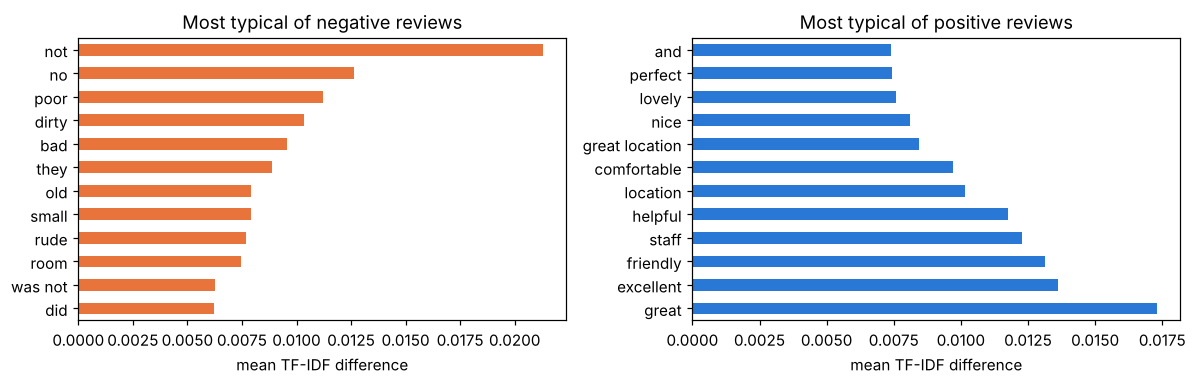

In [13]:
if HAVE_RAW:
    y = train.is_negative.values
    diff = np.asarray(Xtr[y == 1].mean(axis=0) - Xtr[y == 0].mean(axis=0)).ravel()
    order = np.argsort(diff)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
    pd.Series(diff[order[-12:]], vocab[order[-12:]]).plot.barh(ax=ax[0], color="#e8743b"); ax[0].set(title="Most typical of negative reviews", xlabel="mean TF-IDF difference")
    pd.Series(-diff[order[:12]], vocab[order[:12]]).plot.barh(ax=ax[1], color="#2a78d6"); ax[1].set(title="Most typical of positive reviews", xlabel="mean TF-IDF difference")
    plt.tight_layout(); plt.show()
else:
    print(SKIP)

In [14]:
if HAVE_RAW:
    from scipy import sparse
    # words of each hotel's name; a word "identifies" a hotel if most training reviews using it are about hotels with that word in their name
    owners = {}
    for name in train.Hotel_Name.unique():
        for w in set(normalise(name).split()):
            if len(w) > 2 and w in tfidf.vocabulary_:
                owners.setdefault(w, set()).add(name)
    words = sorted(owners)
    cols = [tfidf.vocabulary_[w] for w in words]
    present = (Xtr[:, cols] > 0).astype(np.int32).tocsc()
    hotel_codes, hotel_names = pd.factorize(train.Hotel_Name)
    by_hotel = sparse.csr_matrix((np.ones(len(train)), (hotel_codes, np.arange(len(train))))) @ present     # hotels x words
    by_hotel = by_hotel.toarray(); pos = {h: i for i, h in enumerate(hotel_names)}
    share = np.array([by_hotel[[pos[h] for h in owners[w]], j].sum() / max(by_hotel[:, j].sum(), 1) for j, w in enumerate(words)])
    identifying = [w for w, sh in sorted(zip(words, share), key=lambda t: -t[1]) if sh > 0.5]
    print(f"{len(words):,} words from hotel names are in the vocabulary; {len(identifying)} of them mostly appear in reviews of that hotel, e.g. {', '.join(identifying[:12])}")
else:
    print(SKIP)

662 words from hotel names are in the vocabulary; 183 of them mostly appear in reviews of that hotel, e.g. aitana, aloft, ampersand, andaz, arbor, ayre, batty, berna, britannia, capricorno, chamberlain, dorsett


**Feature-engineering decisions and why**
- **Handle stripped apostrophes.** Kaggle's file stores "wasn't" as "wasn t". An earlier version of the cleaning rule only matched "n't", so on this file it never fired. The tokenizer then dropped the lone "t", and phrases such as "can t clean" lost their negation. The rule now accepts both forms, and a test covers it. Re-running the model with the correction changed test PR-AUC only in the fourth decimal place, so the published conclusions were unaffected, but the code now does what it says.
- **Keep negations; use two-word phrases.** "not clean", "no hot" and "not working" become features in their own right. Part 5 measures that both choices improve PR-AUC.
- **Fit on training hotels only.** The vocabulary, IDF weights and model are fitted together in one scikit-learn `Pipeline`, so no test information reaches training.
- **Hotel-identifying words are in the vocabulary.** Words like these point to a specific hotel rather than to sentiment. That is exactly why a random split would flatter the model: it could recognise a hotel instead of reading sentiment. With hotel-grouped testing, those words can't help on unseen hotels, and SHAP (Part 7) confirms the model doesn't rely on them.
- **Not used as features:**
  - `Average_Score`: target leakage.
  - The word-count columns: derived from the text.
  - Nationality and city: kept only to check subgroups.
  - `Tags`: trip metadata, not sentiment.

## Part 2: validation design

Reviews of the same hotel share vocabulary (its name, street, staff names), so a random split lets the model recognise *hotels* instead of learning *sentiment*. The test set is therefore made of **whole hotels that never appear in training**.

In [15]:
s = metrics["split"]
print(f"training: {s['train_rows']:,} reviews from {s['train_hotels']:,} hotels")
print(f"test:     {s['test_rows']:,} reviews from {s['test_hotels']:,} different hotels")
rob = pd.DataFrame(metrics["robustness"]).T[["pr_auc", "roc_auc", "recall_neg", "precision_neg"]]
display(rob.round(4))

training: 291,580 reviews from 1,193 hotels
test:     72,086 reviews from 299 different hotels


,pr_auc,roc_auc,recall_neg,precision_neg
held-out hotels (primary),0.8495,0.9751,0.8082,0.7306
random rows (leaks hotel context),0.8631,0.9737,0.7960,0.7704
most recent 20% of dates,0.8812,0.9762,0.8031,0.7996


## Part 3: baselines and the final model

PR-AUC is the main metric: only 8.4% of reviews are negative (6.5% in the test hotels), and the team cares about finding them. ROC-AUC would look excellent even for weak models here.

In [16]:
b = pd.DataFrame(metrics["test"]["baselines"]).T[["pr_auc", "roc_auc", "brier"]]
b.loc["final model (TF-IDF 1-2 grams + logistic regression)"] = [metrics["test"]["model"][k] for k in ("pr_auc", "roc_auc", "brier")]
display(b.round(4))
ci = metrics["test"]["model_ci"]
print(f"final model PR-AUC {metrics['test']['model']['pr_auc']:.3f}, 95% CI {ci['pr_auc_95ci'][0]:.3f}-{ci['pr_auc_95ci'][1]:.3f} (hotel-level bootstrap)")
print("regularisation chosen by cross-validation on training hotels only:", metrics["model"]["cv_results"], "-> C =", metrics["model"]["best_C"])

,pr_auc,roc_auc,brier
prior,0.0652,0.5000,0.0615
review_length,0.1300,0.6240,0.2382
tfidf_unigram,0.8011,0.9668,0.0256
tfidf_stopwords_removed,0.7853,0.9636,0.0268
final model (TF-IDF 1-2 grams + logistic regression),0.8495,0.9751,0.0214


final model PR-AUC 0.849, 95% CI 0.820-0.872 (hotel-level bootstrap)
regularisation chosen by cross-validation on training hotels only: {'0.25': 0.8324660563702327, '1.0': 0.8585716164814168, '4.0': 0.8663039141521075} -> C = 4.0


**Is logistic regression the right model family?** Eleven families were compared on the training hotels only (3-fold cross-validation grouped by hotel, TF-IDF fitted inside each fold). Tree ensembles can't use 100,000 sparse columns efficiently, so they get a 200-dimensional LSA (TruncatedSVD) of the same features.

In [17]:
screen = json.loads((REP / "model_screen.json").read_text())
display(pd.DataFrame(screen["table"])[["model", "pr_auc", "pr_auc_sd", "roc_auc", "p_vs_best_holm", "seconds"]].round(4))

,model,pr_auc,pr_auc_sd,roc_auc,p_vs_best_holm,seconds
0,Logistic regression (final model),0.8633,0.0029,0.9735,1.0000,25.5
1,Linear SVM,0.8577,0.0028,0.9717,0.0072,16.3
2,Passive-aggressive,0.8555,0.0030,0.9705,0.0117,6.6
3,SGD (modified Huber loss),0.8511,0.0027,0.9625,0.0022,2.8
4,Ridge classifier,0.8289,0.0026,0.9623,0.0043,12.3
5,Multinomial naive Bayes,0.7951,0.0073,0.9650,0.0117,0.7
6,Complement naive Bayes,0.7897,0.0074,0.9637,0.0117,0.5
7,LSA-200 + histogram gradient boosting,0.7461,0.0068,0.9506,0.0113,314.4
8,LSA-200 + logistic regression,0.7084,0.0071,0.9473,0.0117,11.4
9,LSA-200 + random forest,0.6360,0.0139,0.9238,0.0117,1042.6


**Reading this**
- **The final logistic regression is the best family** (PR-AUC 0.863). Every other family is significantly worse after Holm correction, even with only three folds.
- **Caveat:** the final model was tuned and the others used sensible fixed settings, so the small 0.005 gap to the linear SVM shouldn't be over-read.
- **The large gaps are clear.** Compressing 100,000 n-grams into 200 dimensions throws away the specific sentiment words, so gradient boosting and random forest on those features lose 0.12–0.23 PR-AUC.
- **Bernoulli naive Bayes** only sees whether a word is present, which loses even more.

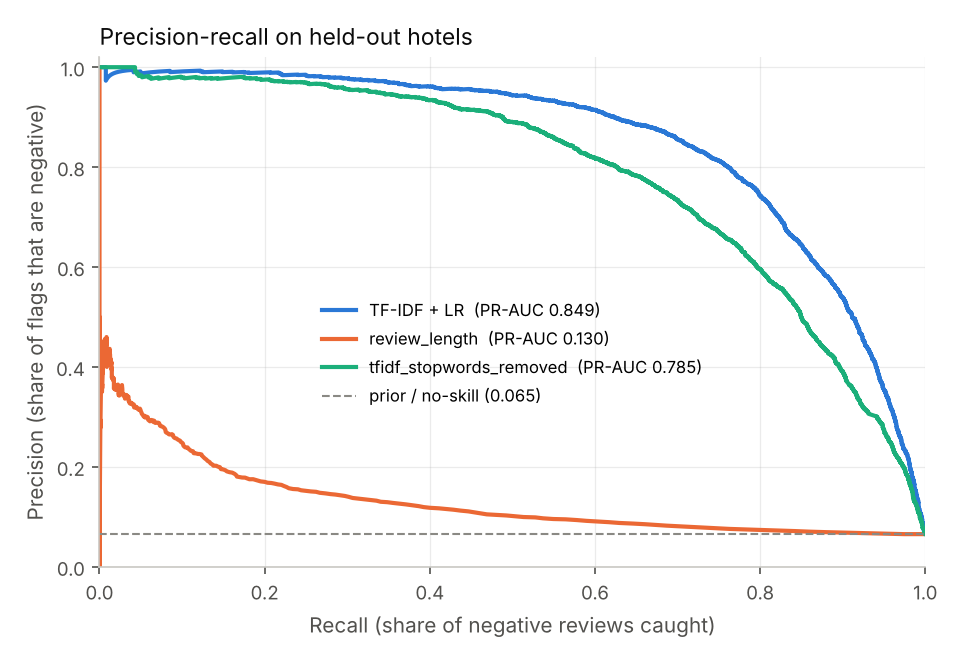

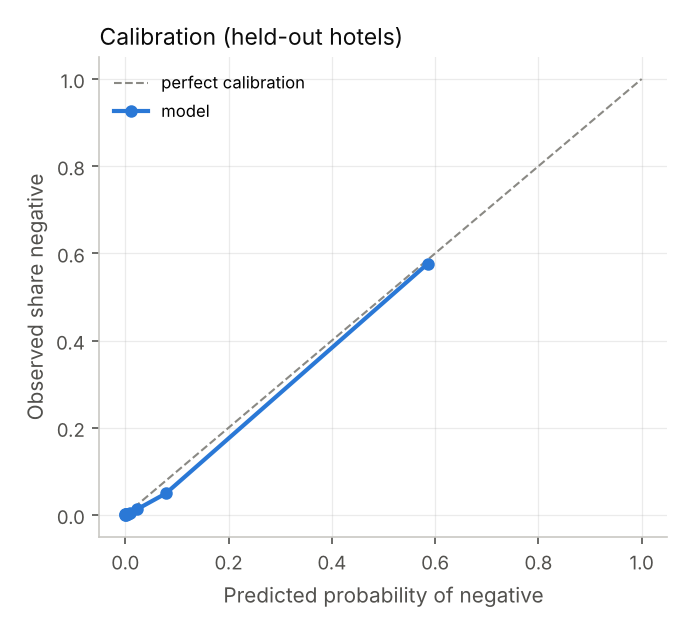

In [18]:
display(Image(filename=str(FIG / "pr_curve.png")))
display(Image(filename=str(FIG / "calibration.png")))

## Part 4: choosing the operating point

The threshold is chosen on **training** data so that about 80% of unhappy guests are caught, and is then checked on the test hotels. In business terms: per 1,000 reviews, how many does the team read, and how many unhappy guests does it reach?

,target recall (set on training),test recall,test precision,share of reviews flagged,per 1000: reviews to read,per 1000: unhappy guests in 1000,per 1000: unhappy caught,per 1000: unhappy missed,per 1000: reads not needed
0,0.70,0.720,0.838,0.056,56,65.2,46.9,18.2,9.1
1,0.80,0.808,0.731,0.072,72,65.2,52.7,12.5,19.4
2,0.90,0.903,0.531,0.111,111,65.2,58.8,6.4,51.9
3,0.95,0.947,0.367,0.168,168,65.2,61.7,3.4,106.4


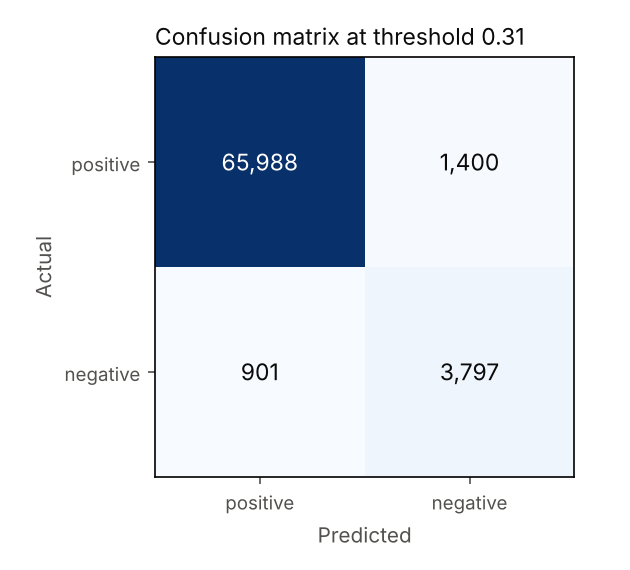

In [19]:
ops = pd.DataFrame([{"target recall (set on training)": o["target_recall_on_train"], "test recall": o["recall"], "test precision": o["precision"],
                     "share of reviews flagged": o["flag_rate"], **{f"per 1000: {k.replace('_', ' ')}": v for k, v in o["per_1000_reviews"].items()}}
                    for o in val["operating_points"]])
display(ops.round(3))
display(Image(filename=str(FIG / "confusion_matrix.png")))

At the chosen point (80% target), the team reads about 7 in every 100 reviews and reaches about 4 in 5 unhappy guests.

## Part 5: is the result robust?

In [20]:
r = val["repeated_splits"]
print(f"5 other hotel splits: PR-AUC {r['pr_auc_mean']:.3f} ± {r['pr_auc_sd']:.3f}, ROC-AUC {r['roc_auc_mean']:.3f} ± {r['roc_auc_sd']:.3f}")
display(pd.DataFrame(val["label_sensitivity"])[["negative_if_score_le", "positive_if_score_ge", "n", "negative_rate", "pr_auc", "roc_auc"]].round(3))

5 other hotel splits: PR-AUC 0.867 ± 0.009, ROC-AUC 0.975 ± 0.002


,negative_if_score_le,positive_if_score_ge,n,negative_rate,pr_auc,roc_auc
0,4.0,9.0,52304,0.030,0.871,0.979
1,5.0,8.0,72086,0.065,0.849,0.975
2,6.0,7.0,91852,0.089,0.732,0.949


In [21]:
u = val["unseen_text"]
print(f"share of test reviews whose exact text also appears in training: {u['share_of_test_with_text_seen_in_training']:.1%}")
print(f"PR-AUC on test reviews with unseen text only: {u['unseen_only']['pr_auc']:.3f}")
sig = pd.DataFrame(val["significance"]).T
sig["95% CI"] = sig["ci95"].apply(lambda c: f"{c[0]:+.3f} to {c[1]:+.3f}")
display(sig[["delta_pr_auc", "95% CI"]].astype({"delta_pr_auc": float}).round(3))

share of test reviews whose exact text also appears in training: 4.2%
PR-AUC on test reviews with unseen text only: 0.855


,delta_pr_auc,95% CI
bigrams vs unigrams only,0.043,+0.036 to +0.051
keeping negations vs stopwords removed,0.058,+0.049 to +0.069
no balancing vs class weights,0.014,+0.012 to +0.018


Design choices were tested, not assumed. Keeping negation words ("not", "no") and adding two-word phrases both improve PR-AUC, and so does *not* using class weights. All three confidence intervals are well above zero.

Behavioural tests probe the model with hand-written sentences:

In [22]:
for name, t in val["behavioural"].items():
    print(f"{t['pass_rate']:.0%} pass  -  {name}")
for name, t in val["behavioural"].items():
    print(); print(name)
    display(pd.DataFrame(t["cases"]))

100% pass  -  negation: adding 'not' to praise should raise the negative score
62% pass  -  negated complaint: 'not dirty' should score less negative than 'dirty'
80% pass  -  invariance: city / hotel name / punctuation should change score by < 0.05

negation: adding 'not' to praise should raise the negative score


,a,b,score_a,score_b,pass
0,the room was clean,the room was not clean,0.129,0.994,True
1,the staff were helpful,the staff were not helpful,0.015,0.967,True
2,the bed was comfortable,the bed was not comfortable,0.008,0.445,True
3,breakfast was good,breakfast was not good,0.021,0.489,True
4,the wifi worked well,the wifi did not work,0.016,0.288,True
5,we would stay here again,we would never stay here again,0.010,0.913,True
6,i was satisfied with the room,i was not satisfied with the room,0.059,0.364,True
7,the hotel was worth the money,the hotel was not worth the money,0.109,0.902,True
8,the shower was hot,there was no hot water in the shower,0.029,0.619,True
9,staff were friendly,staff were not friendly at all,0.074,0.985,True



negated complaint: 'not dirty' should score less negative than 'dirty'


,a,b,score_a,score_b,pass
0,the room was dirty,the room was not dirty,0.997,1.000,False
1,the staff were rude,the staff were not rude,0.987,0.944,True
2,there were problems with the room,there were no problems with the room,0.130,0.181,False
3,it was bad,it was not bad,0.789,0.699,True
4,the room was noisy,the room was not noisy,0.399,0.346,True
5,i had complaints,i had no complaints,0.036,0.015,True
6,the bathroom was small,the bathroom was not small,0.062,0.294,False
7,the location was a problem,the location was not a problem,0.339,0.191,True



invariance: city / hotel name / punctuation should change score by < 0.05


,a,b,score_a,score_b,pass
0,great stay in amsterdam friendly staff,great stay in vienna friendly staff,0.000,0.000,True
1,lovely room at the hotel arena,lovely room at the park plaza,0.001,0.001,True
2,the room was dirty and the staff were rude,"The room was DIRTY, and the staff were rude!!!",1.000,1.000,True
3,breakfast was cold and expensive,breakfast was cold and expensive we visited in june,0.504,0.109,False
4,excellent location close to the metro,excellent location close to the tram,0.000,0.000,True


**An honest result:**
- Negating praise ("the room was not clean") works every time.
- Negating a complaint works in 5 of 8 cases. "not rude" and "not bad" are handled, but "the room was not dirty" still scores as negative as "dirty". In a bag-of-words model, "not" and "dirty" each carry negative weight, and two-word phrases only partly fix it.
- Changing the city, hotel name or punctuation mostly leaves the score unchanged (80% pass).

These are known limits of a linear text model, and a reason to consider a contextual language model in future work.

In [23]:
sub = val["subgroups"]
display(pd.DataFrame(sub["length_band"])[["group", "n", "negative_rate", "pr_auc", "recall", "precision"]].round(3))
display(pd.DataFrame(sub["city"])[["group", "n", "negative_rate", "pr_auc", "recall", "precision"]].round(3))

,group,n,negative_rate,pr_auc,recall,precision
0,1-10 words,18739,0.045,0.640,0.638,0.563
1,11-30,28228,0.049,0.801,0.748,0.691
2,31-80,19886,0.079,0.908,0.869,0.793
3,80+,5233,0.172,0.963,0.952,0.839


,group,n,negative_rate,pr_auc,recall,precision
0,Amsterdam,9047,0.044,0.807,0.797,0.692
1,Barcelona,10138,0.053,0.836,0.808,0.720
2,London,35728,0.075,0.862,0.816,0.739
3,Milan,5257,0.070,0.867,0.828,0.758
4,Paris,8593,0.063,0.850,0.792,0.743
5,Vienna,3323,0.054,0.766,0.730,0.644


Very short reviews are the hardest: a few words carry little signal. Performance is consistent across the six cities.

## Part 6: class imbalance

Only 8.4% of reviews are negative. Common "fixes" were compared on the same hotel split, plus the classic mistake of applying SMOTE **before** splitting.

In [24]:
imb = json.loads((REP / "imbalance_comparison.json").read_text())
display(pd.DataFrame(imb).T[["pr_auc", "roc_auc", "precision_at_80_recall", "recall_at_0.5", "precision_at_0.5", "test_negative_rate"]].round(4))

,pr_auc,roc_auc,precision_at_80_recall,recall_at_0.5,precision_at_0.5,test_negative_rate
no balancing (current model),0.8495,0.9751,0.7429,0.7105,0.8459,0.0652
class_weight='balanced',0.8351,0.9741,0.7082,0.8763,0.5640,0.0652
random oversampling (train only),0.8291,0.9730,0.6896,0.8597,0.5813,0.0652
SMOTE (train only),0.8177,0.9722,0.6735,0.8525,0.5830,0.0652
LEAKY: SMOTE before split (random split),0.9916,0.9930,0.9884,0.9831,0.9545,0.5000
"reference: same random split, no SMOTE",0.8635,0.9738,0.7668,0.6898,0.8701,0.0840


**Reading this:**
- Class weights, oversampling and SMOTE all **lower** PR-AUC. They only move the default threshold, which is better done by choosing the operating point explicitly (Part 4).
- SMOTE applied before the split puts synthetic copies of test reviews into training and turns the test set 50/50. That inflates PR-AUC to about 0.99, a fake result.

## Part 7: explanations (SHAP)

,term,mean_abs_shap,coefficient,share_of_reviews_containing,direction
0,great,0.5108,-17.5858,0.2265,-> positive
1,excellent,0.4363,-18.6556,0.1419,-> positive
2,not,0.2495,11.2238,0.2549,-> negative
3,comfortable,0.2032,-10.6237,0.1379,-> positive
4,lovely,0.1925,-13.5065,0.0810,-> positive
5,helpful,0.1891,-8.4670,0.1782,-> positive
6,perfect,0.1781,-12.1843,0.0707,-> positive
7,amazing,0.1704,-14.4354,0.0567,-> positive
8,friendly,0.1690,-6.7405,0.2009,-> positive
9,nice,0.1249,-6.3779,0.1298,-> positive


SHAP additivity check, max error: 4.4e-15


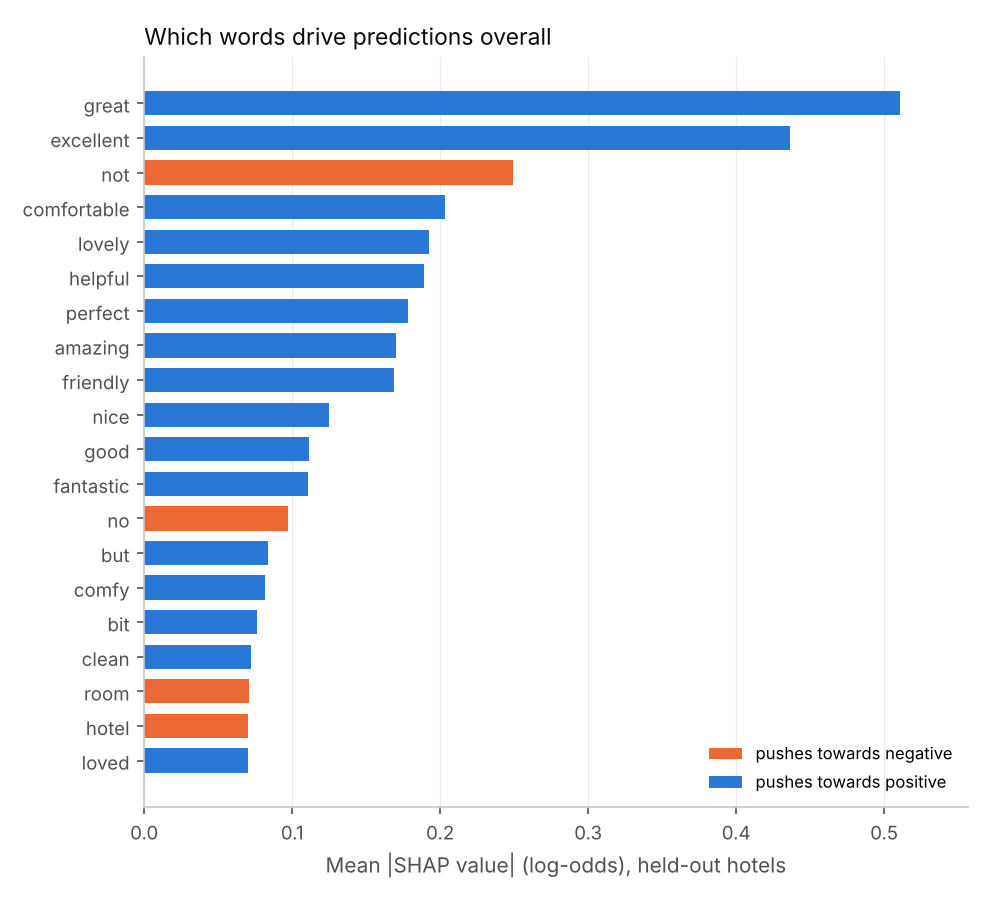

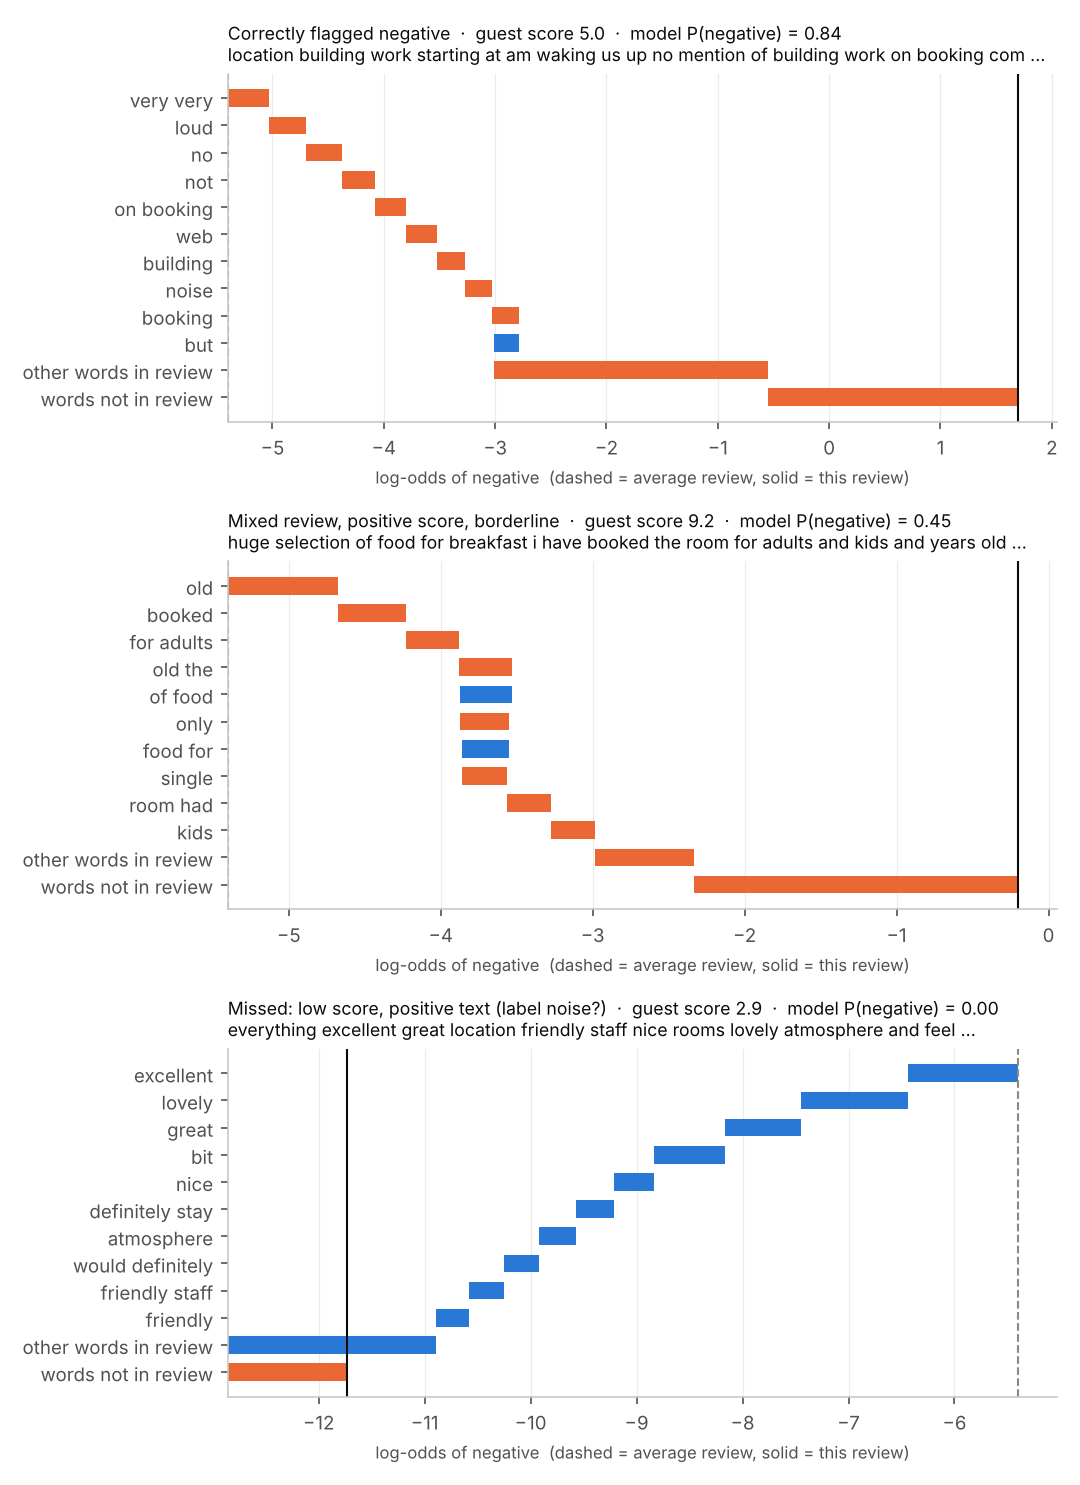

In [25]:
sh = pd.read_csv(REP / "shap_global.csv")
display(sh.head(15).round(4))
ex = json.loads((REP / "shap_examples.json").read_text())
print(f"SHAP additivity check, max error: {ex['additivity_max_abs_error']:.1e}")
display(Image(filename=str(FIG / "shap_global.png")))
display(Image(filename=str(FIG / "shap_examples.png")))

The model relies on genuine sentiment words: "dirty", "rude", "not", "worst" push towards unhappy, and "great", "excellent", "comfortable" towards happy. It does not rely on hotel names or template phrases.

## Part 8: error analysis and conclusions

In [26]:
err = pd.read_csv(REP / "error_analysis.csv")
display(err.groupby("error").head(4)[["error", "Reviewer_Score", "p_negative", "text"]])

,error,Reviewer_Score,p_negative,text
0,false_negative,2.5,2.483417e-10,excellent
1,false_negative,5.0,5.168156e-06,breakfast was perfect
2,false_negative,2.9,8.006845e-06,everything excellent great location friendly staff nice rooms lovely atmosphere and feel would definitely stay again the pillows were a bit lumpy and could do with a couple of extras
3,false_negative,2.5,2.129845e-05,very charming and helpful receptionists beautiful room excellent position near the boulevard saint germain but quiet a wonderful place to stay
25,false_positive,8.3,9.995751e-01,potision wf not saficient
26,false_positive,8.8,9.970994e-01,the manager is rude and bad attitude old man
27,false_positive,8.8,9.963932e-01,the facility is very nice the rooms were great and the proximity to the metro was great as well the staff was horrible unprofessional unsympathetic unkind unpolished unaware we myself and my group of clients booked our rooms on booking com when the rate was better than the rates for existing reservations made directly through the hotel i booked with booking com and canceled the other at arrival the staff said there were no reservations and refused to look for the booking com reservations they would not allow my travel clients to check in after several hours of flight from the u s and were very rude to them the staff even gave my clients an e mail my office sent them which should have been internal information that should not have been forwarded to any client this email clearly outlined the reservation that were canceled it had the reservation numbers as well the staff did not bother to look for the valid reservations and showed no care about the plight my clients faced especially since i was delayed all they had to do was take a few extra minutes to look in their system my flight was delayed but i had a layover in istanbul i called and spoke with the front desk staff gave them the confirmation numbers given by booking com but the staff refused to listen i had to speak with several people incur high phone charges and even raise my voice to force someone to listen to me my client placed me on the phone with receptionist she again reiterated the reservations were canceled i advised her of the valid confirmation number she ignored me repeatedly simply repeating the reservations were canceled i had to literally raise my voice to force her to look up the confirmation number she then said oh i found it but this was after she continued to be rude and unprofessional forcing me in desperation to raise my voice with her it was very frustrating and my clients were very effected by the lack of professionalism and empathy they were shown each day was an issue
28,false_positive,8.8,9.925429e-01,horrible shower


Many "missed" unhappy guests wrote only praise but gave a low score, so the text and the score disagree. No text model can catch those. Many false alarms mention a real problem in an otherwise positive review.

**Conclusions**
1. On hotels it never saw, the model reaches about **4 in 5 unhappy guests by reading about 7% of reviews**, and the result is stable across splits, label definitions and cities.
2. Validating on unseen hotels, and testing every design choice, makes the result defensible.
3. Balancing tricks didn't help, and leaky SMOTE produces fake near-perfect scores.
4. Remaining limits: very short reviews, and reviews whose text doesn't match the score.

See `MODEL_CARD.md` for intended use and limitations.